#### Mount Google Drive
connect Google Drive to this notebook so able to access to dataset zip file.

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Copy and Unzip Dataset from Gdrive folder


In [ ]:
import zipfile
import os

# Updated to the actual path of Celeb-DF-v2 dataset zip file inside Google Drive
zip_file_path = '/content/drive/MyDrive/FYP-2026/sem 2/celeb-df v2 dataset/Celeb-DF-v2.zip'

# Destination folder (current working directory/repository directory)
extract_to_path = os.getcwd()

if os.path.exists(zip_file_path):
    print(f"Extracting {zip_file_path} to {extract_to_path}...")
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to_path)
    print("Extraction complete!")
    print("Updated directory contents:")
    !ls -lh
else:
    print(f"Zip file not found at {zip_file_path}. Please verify the path inside your Google Drive.")

Extracting /content/drive/MyDrive/FYP-2026/sem 2/celeb-df v2 dataset/Celeb-DF-v2.zip to /content/Deepfake-Detection/Deepfake-Detection...
Extraction complete!
Updated directory contents:
total 292K
drwxr-xr-x 4 root root 4.0K Nov  3 19:35 android-app
drwxr-xr-x 2 root root  20K Nov  3 19:36 Celeb-real
drwxr-xr-x 2 root root 216K Nov  3 19:40 Celeb-synthesis
drwxr-xr-x 2 root root 4.0K Nov  3 19:35 docs
-rw-r--r-- 1 root root 1.1K Nov  3 19:35 LICENSE
-rw-r--r-- 1 root root  17K Nov  3 20:51 List_of_testing_videos.txt
drwxr-xr-x 2 root root 4.0K Nov  3 19:35 model
-rw-r--r-- 1 root root 5.0K Nov  3 19:35 README.md
drwxr-xr-x 2 root root  12K Nov  3 19:40 YouTube-real


### Explore and Prepare Dataset for Training
check the directory structure, count the videos in each class, and set up a basic data loader.

In [ ]:
import os

# Define paths based on the extracted folders
base_dir = os.getcwd()
celeb_real_dir = os.path.join(base_dir, 'Celeb-real')
celeb_synthesis_dir = os.path.join(base_dir, 'Celeb-synthesis')
youtube_real_dir = os.path.join(base_dir, 'YouTube-real')

# Count files
num_real = len(os.listdir(celeb_real_dir)) if os.path.exists(celeb_real_dir) else 0
num_synthesis = len(os.listdir(celeb_synthesis_dir)) if os.path.exists(celeb_synthesis_dir) else 0
num_yt_real = len(os.listdir(youtube_real_dir)) if os.path.exists(youtube_real_dir) else 0

print(f"Dataset Directory: {base_dir}")
print(f"Number of Celeb-real videos: {num_real}")
print(f"Number of Celeb-synthesis (Fake) videos: {num_synthesis}")
print(f"Number of YouTube-real videos: {num_yt_real}")


Dataset Directory: /content/Deepfake-Detection/Deepfake-Detection
Number of Celeb-real videos: 590
Number of Celeb-synthesis (Fake) videos: 5639
Number of YouTube-real videos: 300


In [ ]:
import os, re, random
import pandas as pd
from pathlib import Path
from google.colab import files

ROOT = Path(os.getcwd())          # contains Celeb-real and Celeb-synthesis
real = sorted((ROOT/"Celeb-real").glob("*.mp4"))
fake = sorted((ROOT/"Celeb-synthesis").glob("*.mp4"))
print(len(real), "real,", len(fake), "fake")   # expect 590 and 5639

def ids_of(p):                    # real -> ['id0'], fake -> ['id0','id16']
    return re.findall(r"id\d+", p.stem)

# 1) split the PEOPLE (identities seen in the real videos)
people = sorted({ids_of(p)[0] for p in real}, key=lambda s: int(s[2:]))
random.seed(42)
random.shuffle(people)
n = len(people)
n_test, n_val = round(0.20*n), round(0.10*n)
test  = set(people[:n_test])
val   = set(people[n_test:n_test+n_val])
train = set(people[n_test+n_val:])
print(n, "identities ->", len(train), "train,", len(val), "val,", len(test), "test")

def split_of(i):
    return "train" if i in train else "val" if i in val else "test" if i in test else None

# 2) assign videos; a fake is kept only if ALL its identities share one split
rows, dropped = [], 0
for p in real:
    s = split_of(ids_of(p)[0])
    if s: rows.append((p.name, "real", s))
for p in fake:
    splits = {split_of(i) for i in ids_of(p)}
    if len(splits) == 1 and None not in splits:
        rows.append((p.name, "fake", splits.pop()))
    else:
        dropped += 1

df = pd.DataFrame(rows, columns=["video", "label", "split"])
print("fakes dropped (identities straddled two splits):", dropped)
print(df.groupby(["split", "label"]).size().unstack())

# 3) safety check: no identity in two splits
seen = {}
for v, s in zip(df.video, df.split):
    for i in re.findall(r"id\d+", v):
        assert seen.setdefault(i, s) == s, f"LEAK: {i}"
print("No identity appears in more than one split")

out = "/content/drive/MyDrive/FYP-2026/sem 2/splits.csv"
df.to_csv(out, index=False)
files.download(out)

590 real, 5639 fake
59 identities -> 41 train, 6 val, 12 test
fakes dropped (identities straddled two splits): 2632
label  fake  real
split            
test    158   121
train  2810   409
val      39    60
No identity appears in more than one split


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
print(os.getcwd())
print(os.listdir("."))
d = "Celeb-real"
print(os.listdir(d)[:5] if os.path.exists(d) else "Celeb-real NOT found here")

/content/Deepfake-Detection/Deepfake-Detection
['.git', 'Celeb-real', 'YouTube-real', 'docs', '.gitignore', 'Celeb-synthesis', 'LICENSE', 'android-app', 'model', 'List_of_testing_videos.txt', 'README.md']
['id0_0004.mp4', 'id16_0007.mp4', 'id47_0000.mp4', 'id28_0008.mp4', 'id21_0001.mp4']


In [ ]:
!pip install -q mediapipe
!wget -q -O /content/blaze_face_short_range.tflite https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite
!ls -lh /content/blaze_face_short_range.tflite

-rw-r--r-- 1 root root 225K Apr 26  2023 /content/blaze_face_short_range.tflite


In [ ]:
import os, random, shutil, cv2, numpy as np, pandas as pd, mediapipe as mp
from pathlib import Path
from tqdm.auto import tqdm
from mediapipe.tasks import python as mpp
from mediapipe.tasks.python import vision

ROOT   = Path("/content/Deepfake-Detection/Deepfake-Detection")
SPLITS = "/content/drive/MyDrive/FYP-2026/sem 2/splits.csv"
OUT    = Path("/content/faces")
df = pd.read_csv(SPLITS)

detector = vision.FaceDetector.create_from_options(vision.FaceDetectorOptions(
    base_options=mpp.BaseOptions(model_asset_path="/content/blaze_face_short_range.tflite"),
    min_detection_confidence=0.5))

def n_frames(split, label):
    if split == "train":
        return 20 if label == "real" else 3
    return 10

def crop_face(frame):
    h, w = frame.shape[:2]
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.detections:
        return None
    b = max(res.detections, key=lambda d: d.bounding_box.width * d.bounding_box.height).bounding_box
    cx, cy = b.origin_x + b.width / 2, b.origin_y + b.height / 2
    side = max(b.width, b.height) * 1.4          # 20% padding each side
    x1, y1 = int(max(cx - side/2, 0)), int(max(cy - side/2, 0))
    x2, y2 = int(min(cx + side/2, w)), int(min(cy + side/2, h))
    if x2 - x1 < 20 or y2 - y1 < 20:
        return None
    return cv2.resize(frame[y1:y2, x1:x2], (224, 224), interpolation=cv2.INTER_AREA)

def process_video(row):
    folder = "Celeb-real" if row.label == "real" else "Celeb-synthesis"
    cap = cv2.VideoCapture(str(ROOT / folder / row.video))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    k = n_frames(row.split, row.label)
    idxs = np.linspace(0, total - 1, k + 2)[1:-1].astype(int) if total > k else range(total)
    out_dir = OUT / row.split / row.label
    out_dir.mkdir(parents=True, exist_ok=True)
    saved = 0
    for j, i in enumerate(idxs):
        dest = out_dir / f"{Path(row.video).stem}_{j}.jpg"
        if dest.exists():                      # lets you resume after a stop
            saved += 1
            continue
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, frame = cap.read()
        if not ok:
            continue
        face = crop_face(frame)
        if face is not None:
            cv2.imwrite(str(dest), face)
            saved += 1
    cap.release()
    return saved

def run(split, limit=None):
    sub = df[df.split == split]
    if limit:
        sub = sub.sample(limit, random_state=0)
    no_face = 0
    for row in tqdm(list(sub.itertuples()), desc=split):
        if process_video(row) == 0:
            no_face += 1
    print(split, "done. Videos with no usable face:", no_face)

val:   0%|          | 0/20 [00:00<?, ?it/s]

val done. Videos with no usable face: 0
seconds for 20 videos: 0


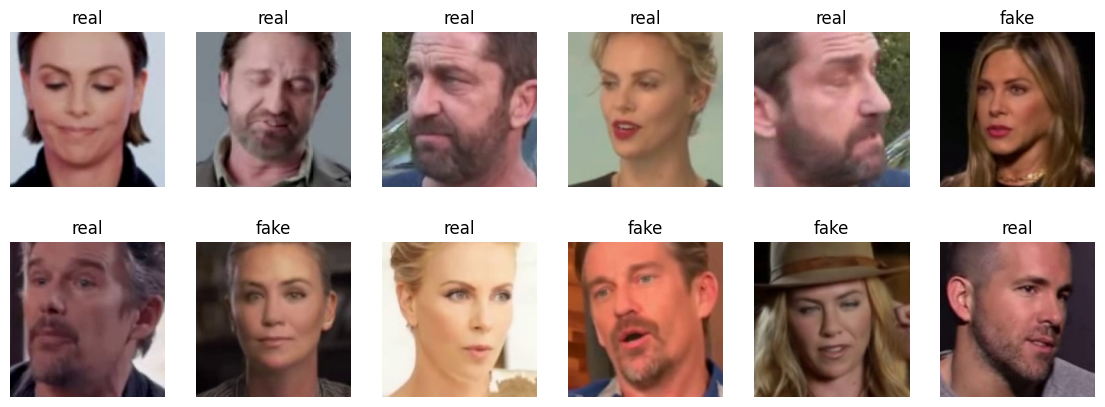

In [ ]:
import time, glob
import matplotlib.pyplot as plt

t = time.time()
run("val", limit=20)
print("seconds for 20 videos:", round(time.time() - t))

files = glob.glob("/content/faces/val/*/*.jpg")
pick = random.sample(files, min(12, len(files)))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, f in zip(axes.flat, pick):
    ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB))
    ax.set_title(f.split("/")[-2]); ax.axis("off")
plt.show()

In [ ]:
for s in ["val", "test", "train"]:
    run(s)
    shutil.make_archive(f"/content/faces_{s}", "zip", OUT / s)
    shutil.copy(f"/content/faces_{s}.zip", "/content/drive/MyDrive/FYP-2026/sem 2/")
    print("saved", s, "zip to Drive")

val:   0%|          | 0/99 [00:00<?, ?it/s]

val done. Videos with no usable face: 0
saved val zip to Drive


test:   0%|          | 0/279 [00:00<?, ?it/s]

test done. Videos with no usable face: 0
saved test zip to Drive


train:   0%|          | 0/3219 [00:00<?, ?it/s]

train done. Videos with no usable face: 14
saved train zip to Drive


train real 8047
train fake 8360
val real 595
val fake 387
test real 1205
test fake 1580


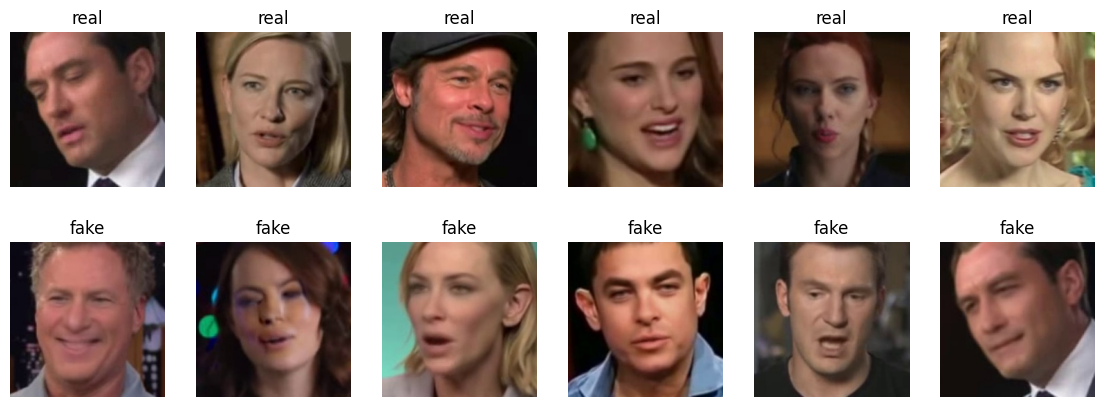

In [ ]:
import glob, random, cv2
import matplotlib.pyplot as plt

for s in ["train", "val", "test"]:
    for l in ["real", "fake"]:
        print(s, l, len(glob.glob(f"/content/faces/{s}/{l}/*.jpg")))

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row, l in enumerate(["real", "fake"]):
    pick = random.sample(glob.glob(f"/content/faces/train/{l}/*.jpg"), 6)
    for ax, f in zip(axes[row], pick):
        ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB))
        ax.set_title(l); ax.axis("off")
plt.show()

**Train MobileNetV3**

load data

In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))   # must show a GPU

FACES = "/content/faces"
BATCH = 32

def load(split, train):
    ds = tf.keras.utils.image_dataset_from_directory(
        f"{FACES}/{split}", labels="inferred", label_mode="binary",
        class_names=["real", "fake"],            # fake = 1
        image_size=(224, 224), batch_size=None, shuffle=train, seed=42)
    if train:
        def augment(img, y):
            img = tf.cast(img, tf.uint8)
            img = tf.image.random_jpeg_quality(img, 30, 75)   # fake TikTok compression
            img = tf.cast(img, tf.float32)
            img = tf.image.random_flip_left_right(img)
            img = tf.image.random_brightness(img, 20.0)
            img = tf.clip_by_value(img, 0.0, 255.0)
            return img, y
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = load("train", True), load("val", False), load("test", False)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 16407 files belonging to 2 classes.
Found 982 files belonging to 2 classes.
Found 2785 files belonging to 2 classes.


build the model

In [ ]:
base = tf.keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet", pooling="avg")
base.trainable = False

inputs = tf.keras.Input((224, 224, 3))
x = base(inputs, training=False)      # keeps batch-norm layers frozen
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc")])

CKPT = "/content/drive/MyDrive/FYP-2026/sem 2/best_model.keras"
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(CKPT, monitor="val_auc", mode="max", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
]

phase 1 trains only the new top layer

In [ ]:
h1 = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=callbacks)

Epoch 1/5
513/513 ━━━━━━━━━━━━━━━━━━━━ 52s 77ms/step - auc: 0.6187 - loss: 0.6819 - val_auc: 0.6026 - val_loss: 0.6551
Epoch 2/5
513/513 ━━━━━━━━━━━━━━━━━━━━ 26s 51ms/step - auc: 0.7157 - loss: 0.6203 - val_auc: 0.6527 - val_loss: 0.6342
Epoch 3/5
513/513 ━━━━━━━━━━━━━━━━━━━━ 27s 52ms/step - auc: 0.7372 - loss: 0.6020 - val_auc: 0.6743 - val_loss: 0.6237
Epoch 4/5
513/513 ━━━━━━━━━━━━━━━━━━━━ 23s 45ms/step - auc: 0.7472 - loss: 0.5938 - val_auc: 0.6700 - val_loss: 0.6280
Epoch 5/5
513/513 ━━━━━━━━━━━━━━━━━━━━ 42s 47ms/step - auc: 0.7481 - loss: 0.5937 - val_auc: 0.6827 - val_loss: 0.6198


phase 2 fine-tunes the pretrained layers

In [ ]:
base.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc")])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 130s 157ms/step - auc: 0.6595 - loss: 0.7539 - val_auc: 0.6987 - val_loss: 0.6543
Epoch 2/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 47s 92ms/step - auc: 0.7800 - loss: 0.5787 - val_auc: 0.7707 - val_loss: 0.6391
Epoch 3/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 46s 90ms/step - auc: 0.8593 - loss: 0.4680 - val_auc: 0.8400 - val_loss: 0.5662
Epoch 4/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 47s 91ms/step - auc: 0.9089 - loss: 0.3817 - val_auc: 0.8852 - val_loss: 0.4654
Epoch 5/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 46s 89ms/step - auc: 0.9367 - loss: 0.3210 - val_auc: 0.9159 - val_loss: 0.3780
Epoch 6/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 48s 93ms/step - auc: 0.9550 - loss: 0.2713 - val_auc: 0.9318 - val_loss: 0.3352
Epoch 7/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 47s 91ms/step - auc: 0.9652 - loss: 0.2391 - val_auc: 0.9390 - val_loss: 0.3165
Epoch 8/10
513/513 ━━━━━━━━━━━━━━━━━━━━ 46s 90ms/step - auc: 0.9749 - loss: 0.2036 - val_auc: 0.9487 - val_loss: 0.2897
Epoch 9/10
513/513 ━━━━━━━━━━━━━━━━━━━

In [ ]:
import numpy as np, tensorflow as tf, pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

FACES = Path("/content/faces")
MODEL = "/content/drive/MyDrive/FYP-2026/sem 2/best_model.keras"
model = tf.keras.models.load_model(MODEL)

def load_eval(split):
    ds = tf.keras.utils.image_dataset_from_directory(
        FACES/split, class_names=["real","fake"], label_mode="binary",
        image_size=(224,224), batch_size=64, shuffle=False)   # fake = 1, same as training
    y = np.concatenate([l.numpy() for _, l in ds]).ravel().astype(int)
    p = model.predict(ds, verbose=0).ravel()                   # P(fake)
    return ds, ds.file_paths, y, p

ds_te, fp_te, yf, pf = load_eval("test")
print("Frame AUC:", roc_auc_score(yf, pf))
print("F1 @0.5:", f1_score(yf, pf > 0.5))
print(confusion_matrix(yf, pf > 0.5))              # rows: real, fake

df = pd.DataFrame({"vid":[Path(f).stem.rsplit("_",1)[0] for f in fp_te], "pf":pf, "yf":yf})
print(df.vid.head(5).tolist())
v = df.groupby("vid").agg(pf=("pf","mean"), yf=("yf","max"))
print("Videos:", len(v), "| Video AUC:", roc_auc_score(v.yf, v.pf))

fake_idx = 1

Found 2785 files belonging to 2 classes.
Frame AUC: 0.966586743001208
F1 @0.5: 0.8989731699238158
[[1123   82]
 [ 223 1357]]
['id11_0000', 'id11_0000', 'id11_0000', 'id11_0000', 'id11_0000']
Videos: 279 | Video AUC: 0.9913693901035674


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np, tensorflow as tf

def tflite_auc(model_bytes, idx):
    it = tf.lite.Interpreter(model_content=model_bytes,
        experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    pq = []
    for i in idx:
        im = tf.keras.utils.img_to_array(tf.keras.utils.load_img(fp_te[i], target_size=(224,224)))
        it.set_tensor(inp["index"], im[None].astype(inp["dtype"]))
        it.invoke(); pq.append(it.get_tensor(out["index"])[0,0])
    print("Input:", inp["dtype"], inp["shape"], "| Output:", out["dtype"])
    return roc_auc_score(yf[idx], np.array(pq))

idx = np.random.RandomState(0).choice(len(fp_te), 600, replace=False)
int8_bytes = open("/content/edgeguard_model.tflite","rb").read()
print("INT8 AUC:", tflite_auc(int8_bytes, idx), "| Keras AUC (same frames):", roc_auc_score(yf[idx], pf[idx]))

# safer backup: float16 version
conv = tf.lite.TFLiteConverter.from_saved_model("/content/saved_model")
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.target_spec.supported_types = [tf.float16]
fp16 = conv.convert()
open("/content/edgeguard_model_fp16.tflite","wb").write(fp16)
print("FP16 size MB:", len(fp16)/1e6, "| FP16 AUC:", tflite_auc(fp16, idx))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Input: <class 'numpy.float32'> [  1 224 224   3] | Output: <class 'numpy.float32'>
INT8 AUC: 0.6452073350947114 | Keras AUC (same frames): 0.9678921678384309


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Input: <class 'numpy.float32'> [  1 224 224   3] | Output: <class 'numpy.float32'>
FP16 size MB: 6.03754 | FP16 AUC: 0.9747548251309839


In [ ]:
model.export("/content/saved_model")        # export the NEW model
conv = tf.lite.TFLiteConverter.from_saved_model("/content/saved_model")
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.target_spec.supported_types = [tf.float16]
fp16 = conv.convert()
open("/content/edgeguard_model.tflite","wb").write(fp16)
print("FP16 size MB:", len(fp16)/1e6, "| FP16 AUC:", tflite_auc(fp16, idx),
      "| Keras AUC (same frames):", roc_auc_score(yf[idx], pf[idx]))

Saved artifact at '/content/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  138074915126352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915118672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915112528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915113680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915113104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915111376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915112912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915119056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915111568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915113296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138074915

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Input: <class 'numpy.float32'> [  1 224 224   3] | Output: <class 'numpy.float32'>
FP16 size MB: 6.039812 | FP16 AUC: 0.9695826429626977 | Keras AUC (same frames): 0.9678921678384309


In [ ]:
import shutil
from google.colab import files
shutil.copy("/content/edgeguard_model.tflite", "/content/drive/MyDrive/FYP-2026/sem 2/edgeguard_model.tflite")
files.download("/content/edgeguard_model.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
ds_va, fp_va, yv, pv = load_eval("val")
dv = pd.DataFrame({"vid":[Path(f).stem.rsplit("_",1)[0] for f in fp_va], "pf":pv, "yf":yv})

def alert_rate(d, thr, win=5, need=4):
    res = {}
    for vid, g in d.groupby("vid"):
        a = (g.pf.values > thr).astype(int)
        hit = any(a[i:i+win].sum() >= need for i in range(max(1, len(a)-win+1)))
        res[vid] = (hit, g.yf.max())
    r = pd.DataFrame(res, index=["hit","fake"]).T
    return r[r.fake==0].hit.mean(), r[r.fake==1].hit.mean()

for thr in [0.5,0.6,0.7,0.8,0.9]:
    fa, tp = alert_rate(dv, thr)
    print(f"VAL thr={thr}: real videos wrongly alerted={fa:.2f} | fake videos caught={tp:.2f}")

Found 982 files belonging to 2 classes.
VAL thr=0.5: real videos wrongly alerted=0.05 | fake videos caught=0.87
VAL thr=0.6: real videos wrongly alerted=0.00 | fake videos caught=0.85
VAL thr=0.7: real videos wrongly alerted=0.00 | fake videos caught=0.82
VAL thr=0.8: real videos wrongly alerted=0.00 | fake videos caught=0.77
VAL thr=0.9: real videos wrongly alerted=0.00 | fake videos caught=0.46


In [49]:
fa, tp = alert_rate(df, 0.7)
print(f"TEST thr=0.7: real videos wrongly alerted={fa:.2f} | fake videos caught={tp:.2f}")

TEST thr=0.7: real videos wrongly alerted=0.01 | fake videos caught=0.82
